# A PyTorch loss on the GPU with `PatchEngine` and `SpectrumEngine`

The Python engines give the statistics **and their exact vector–Jacobian product**, so they plug
into PyTorch as `torch.autograd.Function`s. [Example 06](differentiable) wraps the three engines
for host tensors (`examples/06_differentiable_python/stl_torch.py`) and runs masked synthesis,
patch synthesis and denoising on a laptop CPU. This notebook shows the **GPU path**, the one for
training a network on a GPU:

- `PatchEngine(backend="gpu")` reads the patches from a CUDA tensor and returns their gradient as a
  CUDA tensor (`forward_device`, `vjp_device`): the maps never leave the device;
- `SpectrumEngine(backend="gpu")` runs its transforms on the device (through host arrays, with
  the `spectrum` wrapper of example 06).

The loss holds the scattering statistics of 32 disc patches and the full-sky power spectrum of the
Takahashi κ map at nside 64; it is minimised over the pixels of a map with Adam, as the output of
a network would be. Run time: about two minutes on one Tesla T4.

In [1]:
import json, os, subprocess, sys, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "Cargo.toml").exists():          # the repository root, from docs/tutorials
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "examples"))
sys.path.insert(0, str(ROOT / "python" / "stl_ensemble"))
BIN = Path(os.environ.get("STL_BIN", ROOT / "target" / "release"))
WORK = Path(os.environ.get("STL_WORK", ROOT / "docs" / "tutorials" / "out")); WORK.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "image.cmap": "plasma"})

def run(*args):
    """Runs a command-line tool, prints its last lines and its wall-clock time."""
    t0 = time.time()
    p = subprocess.run([str(a) for a in args], capture_output=True, text=True)
    if p.returncode:
        raise RuntimeError(p.stderr[-2000:])
    print(p.stdout.strip()[-600:], f"\n[{time.time() - t0:.1f} s]")

In [2]:
import torch
sys.path.insert(0, str(ROOT / "examples" / "06_differentiable_python"))
from stl_torch import spectrum                       # host wrapper of SpectrumEngine (example 06)
from stl_port.native import PatchEngine, SpectrumEngine
dev = torch.device("cuda")

class DevicePatches(torch.autograd.Function):
    # Statistics of the selected discs of a GPU PatchEngine, from the patches concatenated in one
    # CUDA tensor (patch i: u[ids[i]]); complex [B, ncoeff] on the device.
    @staticmethod
    def forward(ctx, flat, engine):
        values, _ = engine.forward_device(flat.contiguous(), moments=False)
        ctx.engine = engine
        return torch.from_numpy(values).to(flat.device)

    @staticmethod
    def backward(ctx, g):
        return ctx.engine.vjp_device(g.detach().cpu().numpy()), None

def patch_stats(engine, u, index):
    return DevicePatches.apply(u[index], engine)       # u[index]: autograd scatters the gradient back

SCRIPT VERSION: stl_port 2026-10-29-v2-variance-ratio


SCRIPT VERSION: stl_port.native 2026-11-06-v6


## 1. Engines and targets

32 discs of radius 15° (statistics averaged over a 10° core), centred on pixels of the nside-8
grid, and the spectrum up to `ℓ = 3 nside − 1`. The targets are those of the κ map, standardised;
the weights of the statistics are ergodic (`1 / σ²`).

In [3]:
kappa = np.load(ROOT / "fixtures/takahashi/takahashi_r000_zs1_nside64_nested.npy").astype(np.float64)
t = torch.from_numpy((kappa - kappa.mean()) / kappa.std()).to(dev)
nside = 64
t0 = time.time()
pe = PatchEngine(nside, j=4, backend="gpu")
centres = np.arange(0, 768, 24) * (nside // 8) ** 2     # 32 nside-8 pixels, as nside-64 ids
ids = pe.select(centres, radius=15.0, core=10.0)
index = torch.from_numpy(np.concatenate(ids)).to(dev)
print(f"{len(ids)} discs of {min(map(len, ids))} to {max(map(len, ids))} pixels, {pe.ncoeff} coefficients each; "
      f"setup {time.time() - t0:.1f} s")
se = SpectrumEngine(nside, backend="gpu")
with torch.no_grad():
    s_t = patch_stats(pe, t, index)
    _, var_t = pe.forward_device(t[index].contiguous(), moments=True)
    cl_t = spectrum(se, t[None])[0]
w = torch.from_numpy(pe.native_pixels / np.maximum(var_t, 1e-30)).to(dev)   # ergodic weights [B, ncoeff]
ell = slice(2, None)

def loss_fn(u):
    stats, cl = patch_stats(pe, u, index), spectrum(se, u[None])[0]
    l_sc = (w * (stats - s_t).abs() ** 2).mean()
    l_ps = ((torch.log(cl[ell]) - torch.log(cl_t[ell])) ** 2).mean()
    return l_sc, l_ps

32 discs of 834 to 844 pixels, 1474 coefficients each; setup 15.3 s


## 2. Optimisation through autograd

`loss.backward()` calls `vjp_device` for the patches (gradient on the device) and the spectrum's
VJP; Adam updates the map on the device.

600 steps in 101 s; statistics 26 -> 1.01, spectrum 1.28 -> 2.46e-06


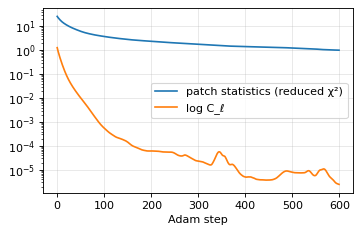

In [4]:
u = torch.randn(12 * nside**2, dtype=torch.float64, device=dev, generator=torch.Generator(dev).manual_seed(0)).requires_grad_()
opt = torch.optim.Adam([u], lr=0.03)
history = []
t0 = time.time()
for step in range(600):
    opt.zero_grad()
    l_sc, l_ps = loss_fn(u)
    (l_sc + l_ps).backward()
    opt.step()
    history.append((l_sc.item(), l_ps.item()))
h = np.array(history)
print(f"600 steps in {time.time() - t0:.0f} s; statistics {h[0, 0]:.3g} -> {h[-1, 0]:.3g}, spectrum {h[0, 1]:.3g} -> {h[-1, 1]:.3g}")
plt.figure(figsize=(5, 3)); plt.semilogy(h[:, 0], label="patch statistics (reduced χ²)"); plt.semilogy(h[:, 1], label="log C_ℓ")
plt.xlabel("Adam step"); plt.legend(); plt.grid(alpha=0.3); plt.show()

Inside the discs the statistics approach the target's (the reduced χ² keeps falling: a network
or a longer run would continue); outside them only the power spectrum constrains the map, which
stays noise-like there.

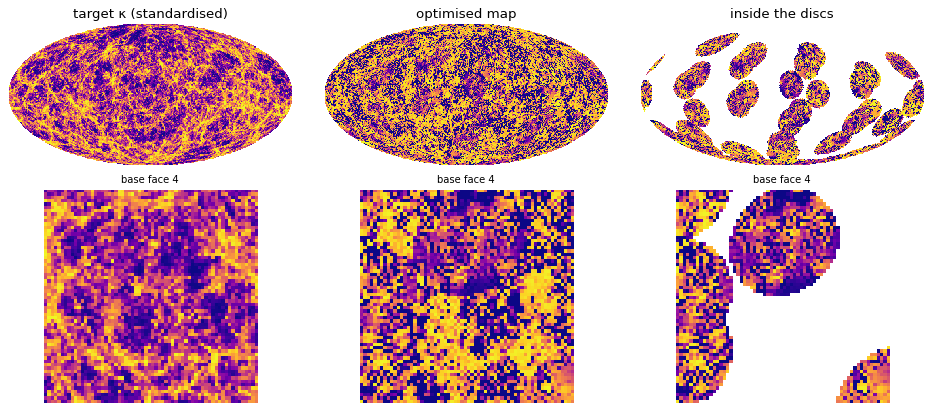

In [5]:
from plotting import mollweide_index, face_image, hist_norm
get_ipython().run_line_magic("matplotlib", "inline")    # plotting.py selects Agg for scripts

def show_maps(maps, titles, face=4, width=420):
    """Mollweide views and one base face of NESTED maps, on the histogram-equalised colour
    scale of the first map (healpy's norm='hist'), shared by all panels."""
    f = hist_norm(maps[0])
    nside = int(round((maps[0].size / 12) ** 0.5))
    idx = mollweide_index(nside, width)
    fig, ax = plt.subplots(2, len(maps), figsize=(4.0 * len(maps), 5.2), squeeze=False,
                           gridspec_kw={"height_ratios": [1, 1.5]})
    for k, (m, t) in enumerate(zip(maps, titles)):
        v = np.where(np.isnan(m), np.nan, f(m))                    # NaN: not shown (grey)
        ax[0, k].imshow(np.where(idx >= 0, v[np.maximum(idx, 0)], np.nan), vmin=0, vmax=1, interpolation="nearest")
        ax[0, k].set_title(t)
        ax[1, k].imshow(face_image(v, face), vmin=0, vmax=1, interpolation="nearest")
        ax[1, k].set_title(f"base face {face}", fontsize=9)
    for a in ax.flat:
        a.axis("off")
        a.set_facecolor("0.85")
    plt.tight_layout(); plt.show()

inside = np.full(t.numel(), np.nan); inside[np.concatenate(ids)] = 1.0
show_maps([t.cpu().numpy(), u.detach().cpu().numpy(), u.detach().cpu().numpy() * inside],
          ["target κ (standardised)", "optimised map", "inside the discs"])

## 3. Gradient check

The gradient of the patch term computed on the GPU (through `vjp_device` and autograd's scatter
of `u[index]`) against the same gradient from the CPU `PatchEngine` on the same discs (its `vjp`,
summed back onto the sky by hand). A finite difference would not do: the GPU evaluations agree
with each other to about 1e-12, which a step small enough to avoid the kinks of `|z|` amplifies
to about 1e-4 of the directional derivative.

In [6]:
v = u.detach().clone().requires_grad_(True)
l_sc, _ = loss_fn(v)
l_sc.backward()
g_gpu = v.grad.cpu().numpy()

cpu = PatchEngine(nside, j=4, threads=8)
cpu.select(centres, radius=15.0, core=10.0)
values, _ = cpu.forward(cpu.gather(v.detach().cpu().numpy()), moments=False)
wn, st = w.cpu().numpy(), s_t.cpu().numpy()
cot = 2 * wn * (values - st) / wn.size                       # d l_sc / d Re + i d l_sc / d Im
g_cpu = np.zeros(v.numel())
for i, gi in zip(cpu.ids, cpu.vjp(cot)):
    np.add.at(g_cpu, i, gi)
print(f"statistics: GPU vs CPU {np.abs(s_t.cpu().numpy() - cpu.forward(cpu.gather(t.cpu().numpy()), moments=False)[0]).max():.1e}")
print(f"gradient: max |GPU - CPU| / max |CPU| = {np.abs(g_gpu - g_cpu).max() / np.abs(g_cpu).max():.1e}")

statistics: GPU vs CPU 4.4e-15
gradient: max |GPU - CPU| / max |CPU| = 1.8e-11
